# Income data – sanity checks
Quick visual checks of the cleaned income tables produced by `src/income/clean_income.py`.
Run the scripts first (see README), then run this notebook from the `notebooks/` folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

income = pd.read_csv('../data/processed/income_canton_year.csv')
income.head()

,year,canton_nr,canton_abbr,canton_name,grossregion_code,grossregion,stpf,mean_steink,median_steink,gini_steink,mean_reink,median_reink,p25,p75,median_steink_index_2012,median_steink_yoy_pct,yoy_outlier,annual_gross_wage_region,wage_interpolated,taxable_income_to_wage_ratio
0,2012,1,ZH,Zürich,4,Zürich,860401,65835.0,50000.0,0.491,73497.0,56000.0,25000.0,79300.0,100.0,NaN,False,82800.0,False,0.6039
1,2012,2,BE,Bern,2,Espace Mittelland,630000,48823.0,41900.0,0.462,56087.0,47400.0,19100.0,64200.0,100.0,NaN,False,75696.0,False,0.5535
2,2012,3,LU,Luzern,6,Zentralschweiz,227146,54463.0,44700.0,0.448,62574.0,50800.0,24200.0,66800.0,100.0,NaN,False,75756.0,False,0.5901
3,2012,4,UR,Uri,6,Zentralschweiz,20489,48285.0,43600.0,0.395,56516.0,50000.0,24100.0,62300.0,100.0,NaN,False,75756.0,False,0.5755
4,2012,5,SZ,Schwyz,6,Zentralschweiz,89211,84278.0,48400.0,0.596,92177.0,54900.0,25900.0,77300.0,100.0,NaN,False,75756.0,False,0.6389


## Median taxable income per canton, 2012–2022
Indexed to 2012 = 100 so that growth is comparable between rich and poor cantons.

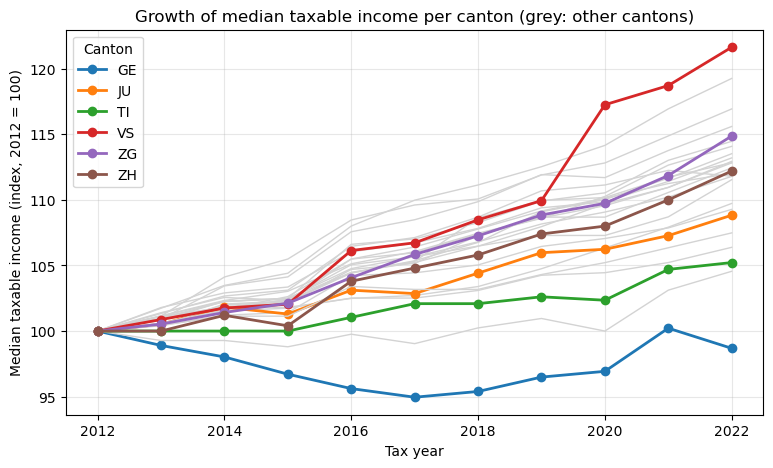

In [2]:
highlight = ['ZG', 'ZH', 'GE', 'TI', 'VS', 'JU']
fig, ax = plt.subplots(figsize=(9, 5))
for abbr, g in income.groupby('canton_abbr'):
    if abbr in highlight:
        ax.plot(g['year'], g['median_steink_index_2012'], marker='o', lw=2, label=abbr)
    else:
        ax.plot(g['year'], g['median_steink_index_2012'], color='lightgrey', lw=1)
ax.set(xlabel='Tax year', ylabel='Median taxable income (index, 2012 = 100)',
       title='Growth of median taxable income per canton (grey: other cantons)')
ax.legend(title='Canton')
ax.grid(alpha=0.3)
plt.show()

## Level in 2022

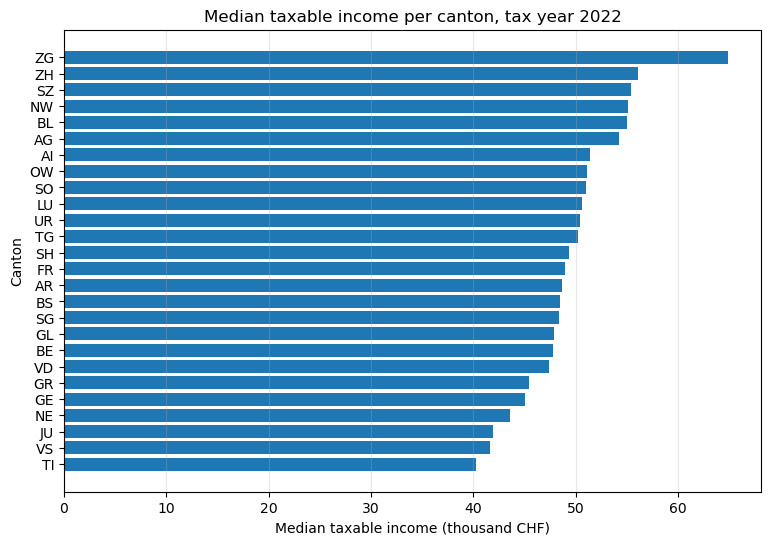

In [3]:
y2022 = income.query('year == 2022').sort_values('median_steink')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(y2022['canton_abbr'], y2022['median_steink'] / 1000)
ax.set(xlabel='Median taxable income (thousand CHF)', ylabel='Canton',
       title='Median taxable income per canton, tax year 2022')
ax.grid(axis='x', alpha=0.3)
plt.show()

## Cross-check: ESTV taxable income vs. BFS gross wage
The BFS wage is only available per large region, so every canton of a region gets the same wage. Taxable income is lower than gross wage because of deductions and because it is counted per tax unit.

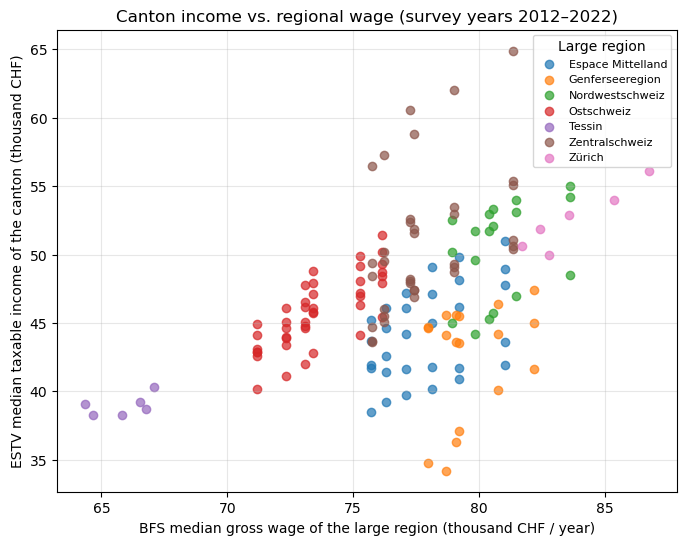

Correlation: 0.46


In [4]:
survey_years = income.query('not wage_interpolated')
fig, ax = plt.subplots(figsize=(8, 6))
for region, g in survey_years.groupby('grossregion'):
    ax.scatter(g['annual_gross_wage_region'] / 1000, g['median_steink'] / 1000, label=region, alpha=0.7)
ax.set(xlabel='BFS median gross wage of the large region (thousand CHF / year)',
       ylabel='ESTV median taxable income of the canton (thousand CHF)',
       title='Canton income vs. regional wage (survey years 2012–2022)')
ax.legend(title='Large region', fontsize=8)
ax.grid(alpha=0.3)
plt.show()

print('Correlation:', survey_years[['annual_gross_wage_region', 'median_steink']].corr().iloc[0, 1].round(2))

## Flagged values

In [5]:
income.loc[income['yoy_outlier'], ['year', 'canton_abbr', 'stpf', 'median_steink', 'median_steink_yoy_pct']]

,year,canton_abbr,stpf,median_steink,median_steink_yoy_pct
230,2020,VS,240441,40100.0,6.6489
